# Исследовательский анализ и перекодирование данных Netflix Customer Churn

**Цель:** подготовить датасет к анализу/моделированию оттока, проверить качество данных, визуализировать распределения, реализовать два метода удаления выбросов и перекодировать категориальные признаки.

> Исходный файл: `netflix_customer_churn.csv`. Целевой признак — `churned`: `1` означает отток клиента, `0` — отсутствие оттока.

Блокнот использует `pandas`, `numpy`, `matplotlib` и `scikit-learn`. Он рассчитан на запуск в папке с CSV-файлом; для текущего окружения также предусмотрен путь к прикреплённому файлу.

In [96]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix


## 1. Загрузка и краткое описание данных

In [97]:

df_raw = pd.read_csv('netflix_customer_churn.csv')
df = df_raw.copy()

df.head()


#


,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action


In [98]:

target = "churned"
IDS = ["customer_id"]



print(f'Кол-во строк: {df.shape[0]}')
print(f'Кол-во столбцов: {df.shape[1]}')

print("Целевой признак: ", end="")
print(target)

column_overview = pd.DataFrame({
    "тип данных": df.dtypes.astype(str),
    "непропущенных": df.notna().sum(),
    "пропусков": df.isna().sum(),
    "уникальных значений": df.nunique(dropna=False),
})
column_overview

Кол-во строк: 5000
Кол-во столбцов: 14
Целевой признак: churned


,тип данных,непропущенных,пропусков,уникальных значений
customer_id,object,5000,0,5000
age,int64,5000,0,53
gender,object,5000,0,3
subscription_type,object,5000,0,3
watch_hours,float64,5000,0,2343
last_login_days,int64,5000,0,61
region,object,5000,0,6
device,object,5000,0,5
monthly_fee,float64,5000,0,3
churned,int64,5000,0,2


### Краткое описание

В наборе **5 000 строк и 14 столбцов**:

- `customer_id` — уникальный строковый идентификатор, он исключается из статистического анализа и кодирования;
- 6 категориальных предикторов: `gender`, `subscription_type`, `region`, `device`, `payment_method`, `favorite_genre`;
- 6 количественных предикторов: `age`, `watch_hours`, `last_login_days`, `monthly_fee`, `number_of_profiles`, `avg_watch_time_per_day`;
- `churned` — бинарный целевой признак (`int64`).

Столбцы `monthly_fee`, `number_of_profiles` и `last_login_days` числовые, но принимают дискретные значения; это следует учитывать при интерпретации графиков.

## 2. Проверка качества данных и обработка пропусков

In [99]:

full_duplicates = df.duplicated().sum()
id_duplicates = df["customer_id"].duplicated().sum() if "customer_id" in df.columns else np.nan
missing_before = df.isna().sum().rename("пропусков до обработки")

print(f"Полных дубликатов: {full_duplicates}")
print(f"Дубликатов customer_id: {id_duplicates}")
print("\nПропуски по столбцам:")
print(missing_before.to_string())

Полных дубликатов: 0
Дубликатов customer_id: 0

Пропуски по столбцам:
customer_id               0
age                       0
gender                    0
subscription_type         0
watch_hours               0
last_login_days           0
region                    0
device                    0
monthly_fee               0
churned                   0
payment_method            0
number_of_profiles        0
avg_watch_time_per_day    0
favorite_genre            0


В исходном наборе **нет полных дубликатов и пропусков**, поэтому данные ниже не изменятся. Тем не менее, следующие функции включены для воспроизводимой обработки нового файла с такой же структурой.

Числовые пропуски заполняются **средним значением внутри категории `subscription_type`**. Если для группы среднее вычислить нельзя, используется среднее по всему столбцу. Для текстовых признаков среднее неприменимо, поэтому используется наиболее частое значение в группе, а затем глобальная мода. Пропуски в целевой переменной не заполняются: строки без ответа по оттоку удаляются, так как целевая переменная не должна быть искусственно восстановлена.

In [100]:
def fill_numeric_missing_by_group_mean(data, numeric_columns, group_column):
    """Заполняет NaN в числовых колонках средним внутри group_column.

    При невозможности вычислить групповое среднее использует среднее по колонке.
    Возвращает копию DataFrame и не изменяет исходный объект.
    """
    result = data.copy()

    for column in numeric_columns:
        group_mean = result.groupby(group_column)[column].transform("mean")
        result[column] = result[column].fillna(group_mean)
        result[column] = result[column].fillna(result[column].mean())
    return result


def fill_categorical_missing_by_group_mode(data, categorical_columns, group_column):
    """Заполняет NaN модой внутри группы; нужен для нечисловых признаков."""
    result = data.copy()
    for column in categorical_columns:
        if column == group_column:
            # Для самой группирующей колонки групповой метод неприменим.
            mode = result[column].mode(dropna=True)
            if not mode.empty:
                result[column] = result[column].fillna(mode.iloc[0])
            continue

        group_mode = result.groupby(group_column)[column].transform(
            lambda x: x.dropna().mode().iloc[0] if not x.dropna().mode().empty else np.nan
        )
        result[column] = result[column].fillna(group_mode)
        global_mode = result[column].mode(dropna=True)
        if not global_mode.empty:
            result[column] = result[column].fillna(global_mode.iloc[0])
    return result


numeric_predictors = [
    "age", "watch_hours", "last_login_days", "monthly_fee",
    "number_of_profiles", "avg_watch_time_per_day",
]
categorical_predictors = [
    "gender", "subscription_type", "region", "device", "payment_method", "favorite_genre",
]

# Целевая переменная не имитируется. При её пропуске такую строку исключают.
df_prepared = df.dropna(subset=[target]).copy()
df_prepared = fill_numeric_missing_by_group_mean(
    df_prepared, numeric_predictors, group_column="subscription_type"
)
df_prepared = fill_categorical_missing_by_group_mode(
    df_prepared, categorical_predictors, group_column="subscription_type"
)

quality_after = pd.DataFrame({
    "пропусков до": missing_before,
    "пропусков после": df_prepared.isna().sum(),
})
print(f"Строк после обработки: {len(df_prepared):,}")
quality_after

Строк после обработки: 5,000


,пропусков до,пропусков после
customer_id,0,0
age,0,0
gender,0,0
subscription_type,0,0
watch_hours,0,0
last_login_days,0,0
region,0,0
device,0,0
monthly_fee,0,0
churned,0,0


## 3. Ящики с усами для количественных признаков

Графики показывают медиану, интерквартильный размах (IQR), «усы» и потенциальные выбросы. Признак `churned` намеренно не включён: он бинарный, поэтому boxplot для него неинформативен.

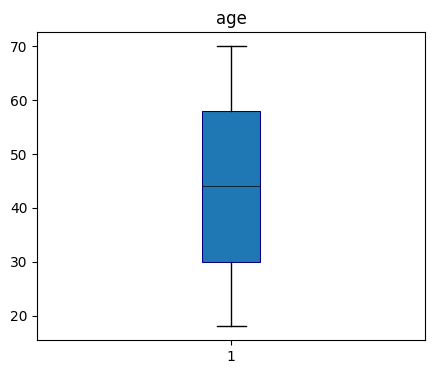

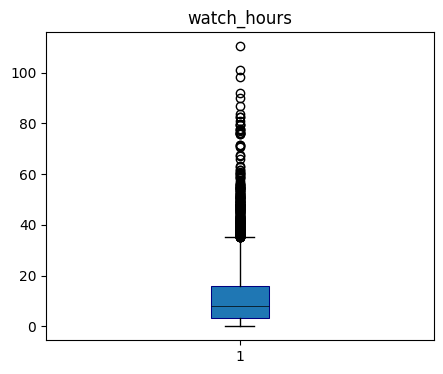

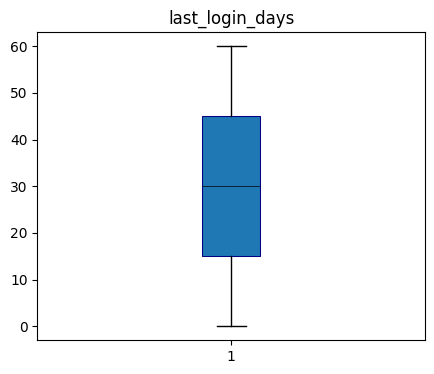

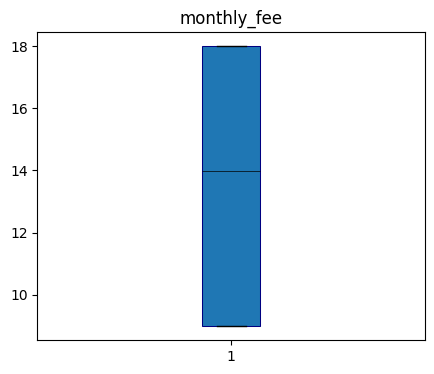

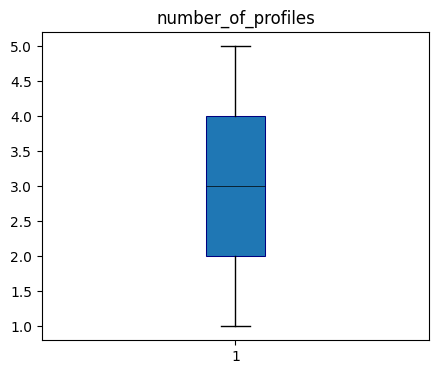

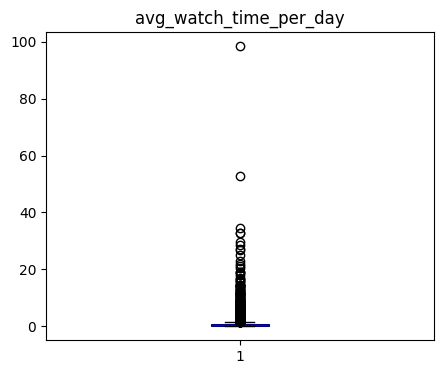

In [101]:
def plot_boxplot(data, feature):
    plt.figure(figsize=(5, 4))
    plt.boxplot(data[feature], patch_artist=True, boxprops=dict( color='navy', linewidth=0.75), medianprops=dict(color='black', linewidth=0.5))
    plt.title(feature)
    
    plt.show()

for i in numeric_predictors:
    plot_boxplot(df_prepared, i)


## 4. Функции удаления выбросов

Обе функции возвращают **копию** датафрейма и не меняют `df_prepared`. В примере ниже обработан `watch_hours`; при практическом моделировании сначала следует согласовать правило обработки с предметной областью, а не удалять наблюдения автоматически.

In [102]:
def remove_outliers_n_std(data, feature, n=3):
    mean = data[feature].mean()
    std = data[feature].std()

    lower = mean - n * std
    upper = mean + n * std

    keep = data[feature].isna() | data[feature].between(lower, upper)
    result = data.loc[keep].copy()

    print(f"{feature}: удалено строк — {len(data) - len(result)}")
    return result


def remove_outliers_iqr(data, feature):
    """Удаляет выбросы по правилу 1,5 × IQR."""
    q1 = data[feature].quantile(0.25)
    q3 = data[feature].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    keep = data[feature].isna() | data[feature].between(lower, upper)
    result = data.loc[keep].copy()

    print(f"{feature}: удалено строк — {len(data) - len(result)}")
    return result


# Пример: два метода применяются к watch_hours отдельно
df_without_outliers_std = remove_outliers_n_std(
    df_prepared, "watch_hours", n=3
)

df_without_outliers_iqr = remove_outliers_iqr(
    df_prepared, "watch_hours"
)

watch_hours: удалено строк — 102
watch_hours: удалено строк — 238


## 5. Универсальные функции визуализации

Следующие функции строят: гистограммы количественных признаков, столбчатые диаграммы распределений категориальных признаков и скрипичные графики зависимости между целевой переменной и предикторами.

In [103]:
def plot_histogram(data, feature, bins=30):
    """Строит гистограмму одного количественного признака."""
    plt.figure(figsize=(6, 4))
    plt.hist(data[feature].dropna(), bins=bins, edgecolor="black")
    plt.title(f"Гистограмма: {feature}")
    plt.xlabel(feature)
    plt.ylabel("Количество")
    plt.show()


def plot_category_counts(data, feature):
    """Строит столбчатую диаграмму одного категориального признака."""
    counts = data[feature].value_counts(dropna=False)

    plt.figure(figsize=(7, 4))
    plt.bar(counts.index.astype(str), counts.values)
    plt.title(f"Распределение: {feature}")
    plt.xlabel(feature)
    plt.ylabel("Количество")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()


def plot_numeric_by_target(data, feature, target=target):
    """Строит скрипичный график количественного признака по классам цели."""
    classes = sorted(data[target].dropna().unique())
    values = [
        data.loc[data[target] == class_value, feature].dropna().values
        for class_value in classes
    ]

    plt.figure(figsize=(6, 4))
    plt.violinplot(values, showmeans=True, showmedians=True)
    plt.title(f"{feature} в зависимости от {target}")
    plt.xlabel(target)
    plt.ylabel(feature)
    plt.xticks(range(1, len(classes) + 1), classes)
    plt.show()


def plot_category_by_target(data, feature, target=target):
    """Показывает распределение целевого признака отдельно по категориям."""
    categories = data[feature].dropna().value_counts().index
    positions = []
    values = []
    labels = []
    churn_rates = []

    for position, category in enumerate(categories, start=1):
        group = data.loc[data[feature] == category, target].dropna().values

        if len(group) == 0:
            continue

        positions.append(position)
        values.append(group)
        labels.append(str(category))
        churn_rates.append(group.mean())

    plt.figure(figsize=(7, 4))

    # Скрипку строим, если в категории достаточно данных и есть разброс.
    for position, group in zip(positions, values):
        if len(group) > 1 and np.unique(group).size > 1:
            plt.violinplot(
                [group],
                positions=[position],
                showmeans=True,
                showmedians=True
            )
        else:
            # Для категории без разброса показываем одну точку.
            plt.scatter(position, group.mean(), color="blue")

    plt.scatter(
        positions,
        churn_rates,
        color="red",
        label="Средняя доля оттока",
        zorder=3
    )
    plt.title(f"{target} в зависимости от {feature}")
    plt.xlabel(feature)
    plt.ylabel(target)
    plt.xticks(positions, labels, rotation=35, ha="right")
    plt.legend()
    plt.tight_layout()
    plt.show()
    plt.show()

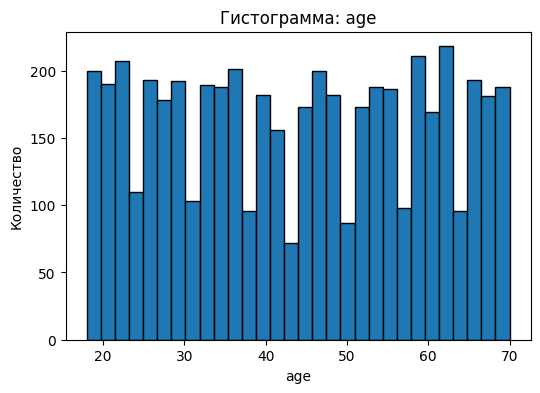

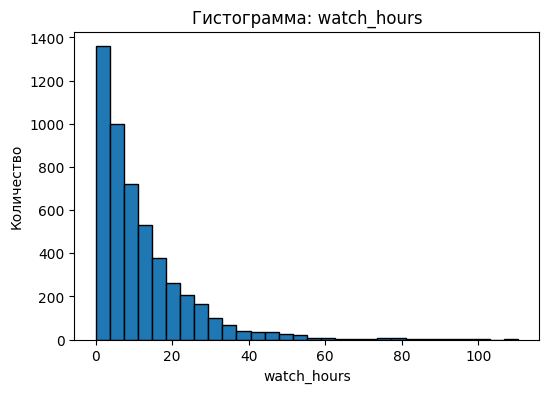

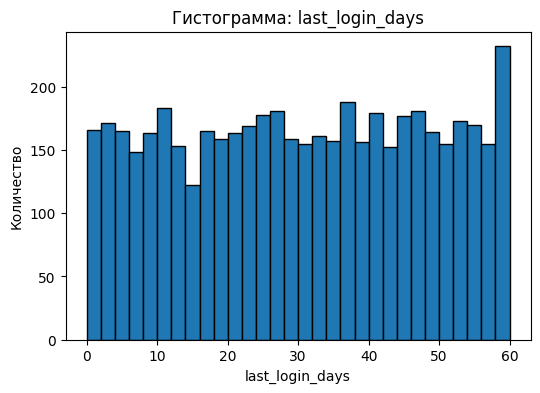

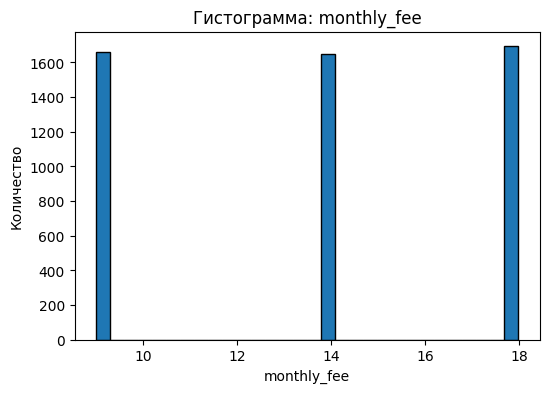

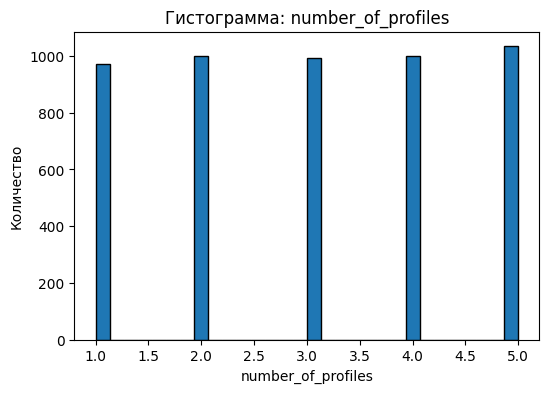

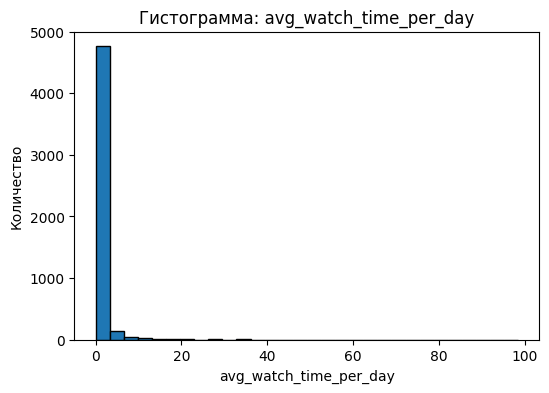

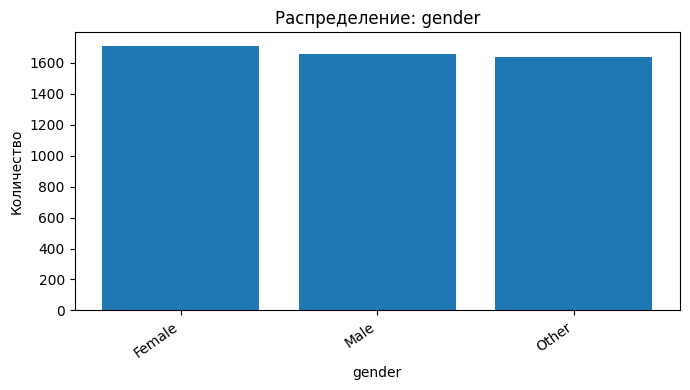

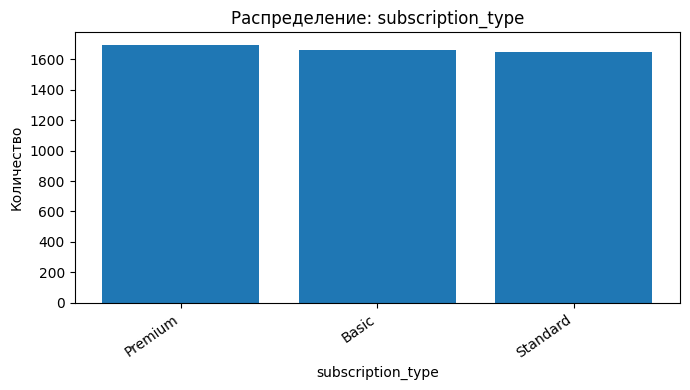

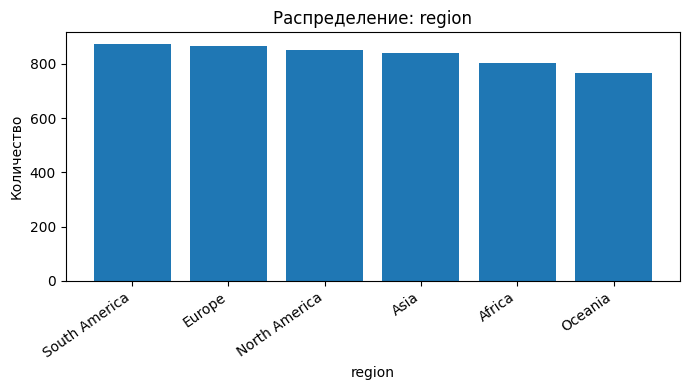

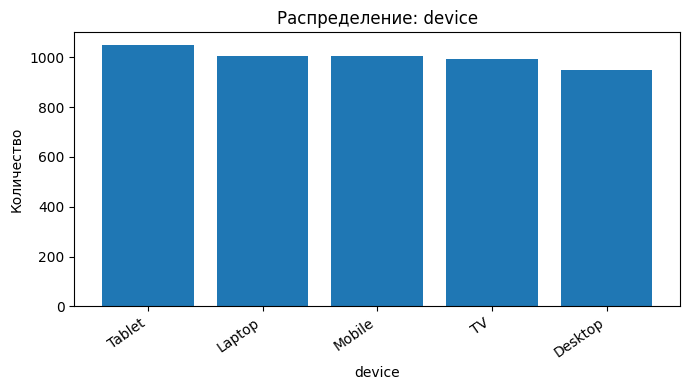

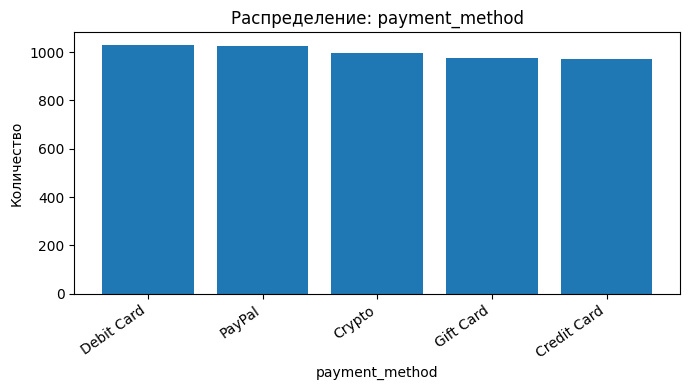

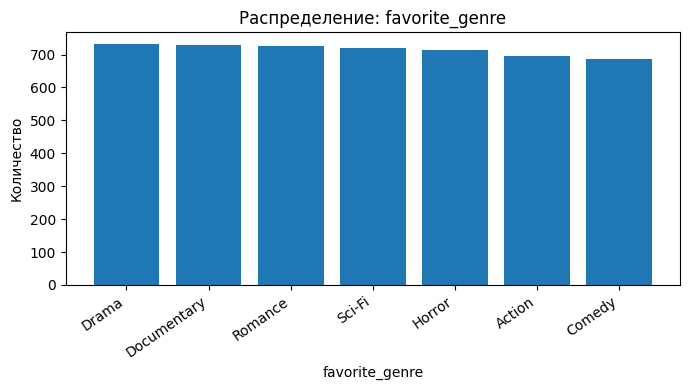

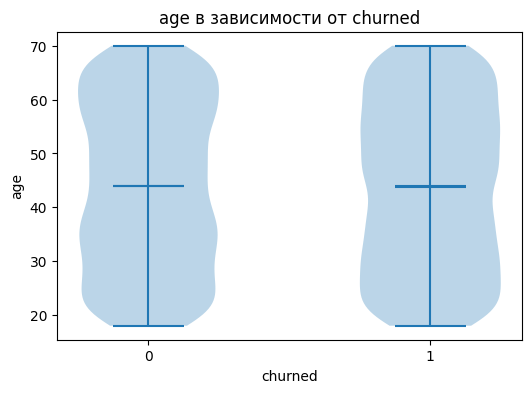

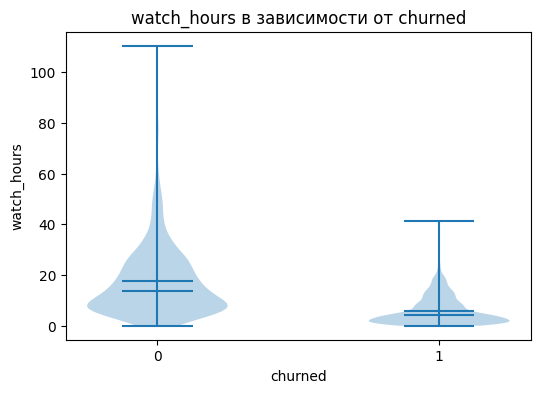

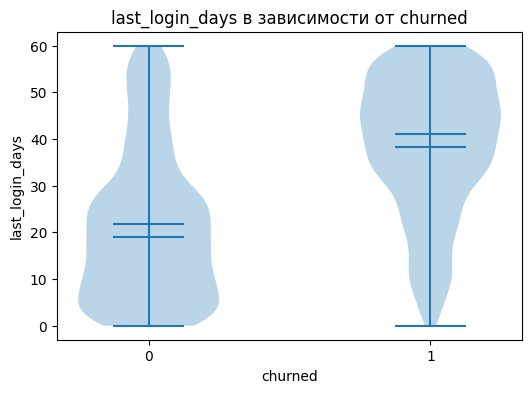

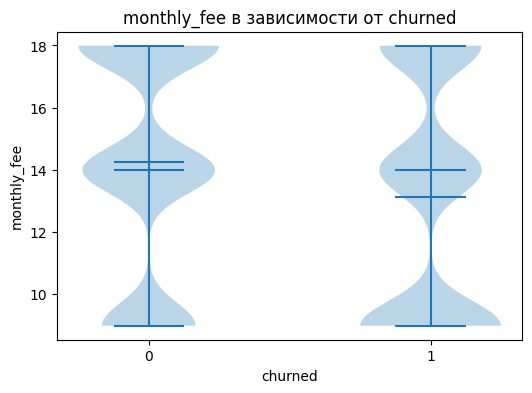

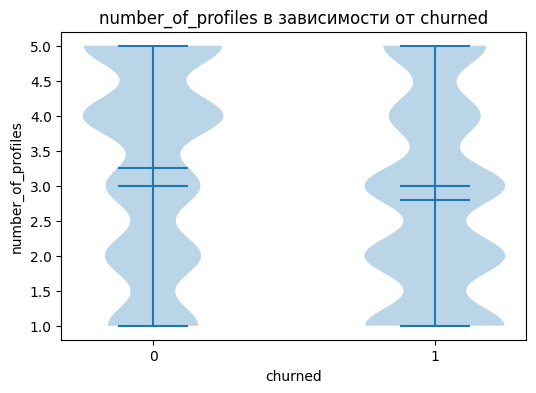

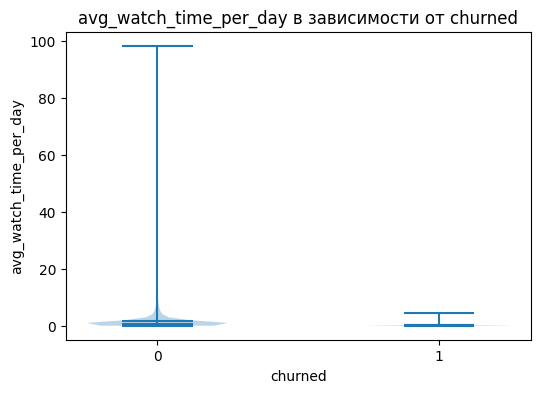

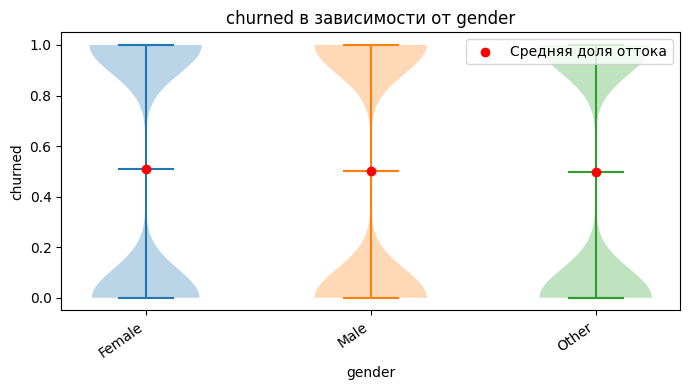

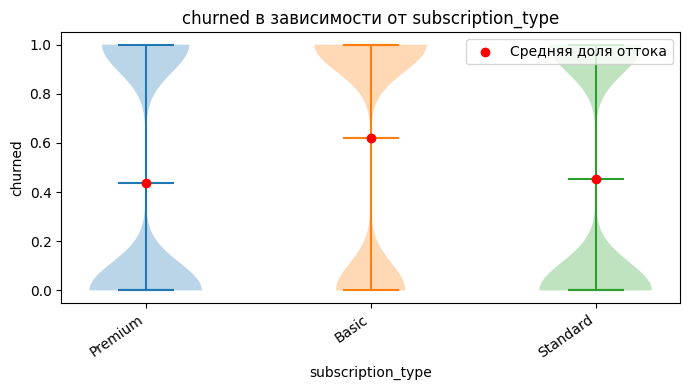

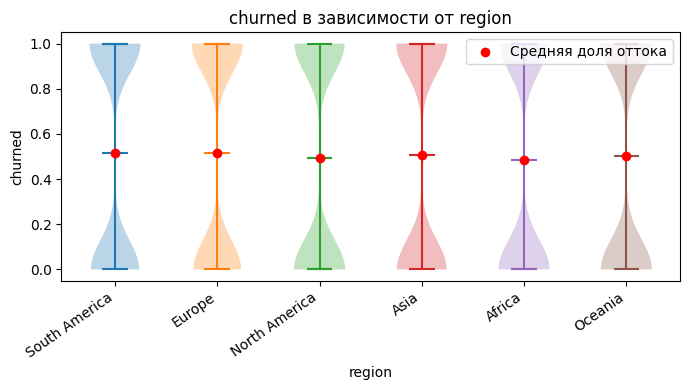

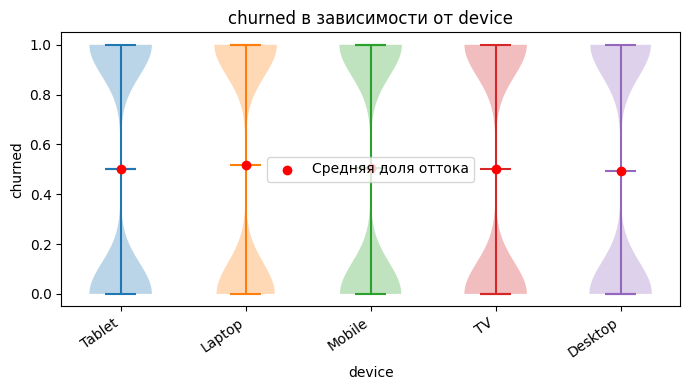

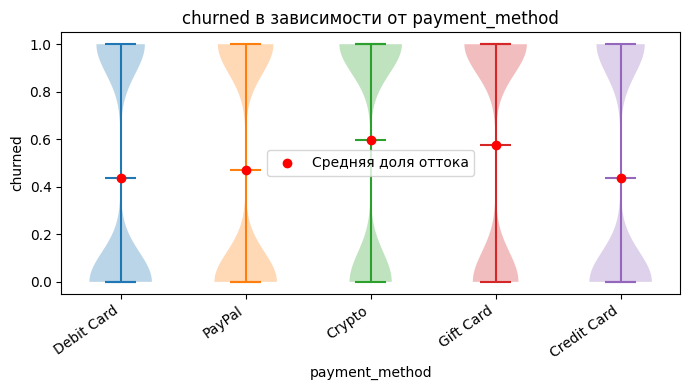

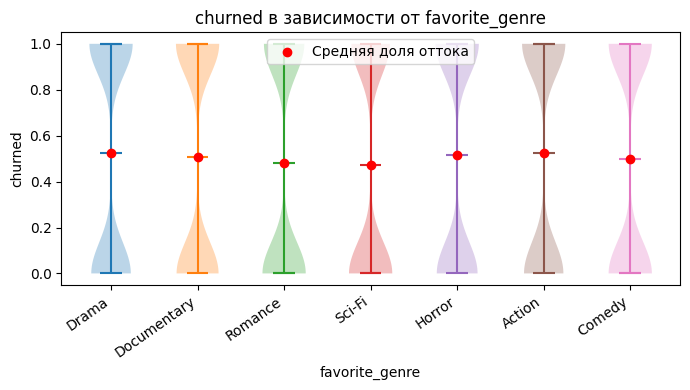

In [104]:
plot_histogram(df_prepared, "age")
plot_histogram(df_prepared, "watch_hours")
plot_histogram(df_prepared, "last_login_days")
plot_histogram(df_prepared, "monthly_fee")
plot_histogram(df_prepared, "number_of_profiles")
plot_histogram(df_prepared, "avg_watch_time_per_day")

plot_category_counts(df_prepared, "gender")
plot_category_counts(df_prepared, "subscription_type")
plot_category_counts(df_prepared, "region")
plot_category_counts(df_prepared, "device")
plot_category_counts(df_prepared, "payment_method")
plot_category_counts(df_prepared, "favorite_genre")

plot_numeric_by_target(df_prepared, "age")
plot_numeric_by_target(df_prepared, "watch_hours")
plot_numeric_by_target(df_prepared, "last_login_days")
plot_numeric_by_target(df_prepared, "monthly_fee")
plot_numeric_by_target(df_prepared, "number_of_profiles")
plot_numeric_by_target(df_prepared, "avg_watch_time_per_day")

plot_category_by_target(df_prepared, "gender")
plot_category_by_target(df_prepared, "subscription_type")
plot_category_by_target(df_prepared, "region")
plot_category_by_target(df_prepared, "device")
plot_category_by_target(df_prepared, "payment_method")
plot_category_by_target(df_prepared, "favorite_genre")

## 6. Описательные статистики целевого признака и интерпретация

In [105]:
print(df[target].describe())

# Количество объектов и доля каждого класса.
target_counts = df[target].value_counts().sort_index()
target_percent = df[target].value_counts(normalize=True).sort_index() * 100

target_summary = pd.DataFrame({
    "Количество": target_counts,
    "Доля, %": target_percent.round(2),
})

display(target_summary)
display(target_summary)


count    5000.000000
mean        0.503000
std         0.500041
min         0.000000
25%         0.000000
50%         1.000000
75%         1.000000
max         1.000000
Name: churned, dtype: float64


,Количество,"Доля, %"
churned,,
0,2485,49.7
1,2515,50.3


,Количество,"Доля, %"
churned,,
0,2485,49.7
1,2515,50.3


### Интерпретация целевого признака

- Наблюдается **2 515 клиентов с оттоком (50,30%)** и **2 485 без оттока (49,70%)**.
- Среднее `churned` равно **0,503**. Для бинарного признака это одновременно оценка доли положительного класса.
- Стандартное отклонение около **0,500** закономерно для почти сбалансированной бинарной переменной; оно максимально близко к 0,5 при доле класса около 50%.
- Значимого дисбаланса классов нет, поэтому на первом этапе не требуется искусственное выравнивание классов. Однако при оценке модели всё равно следует использовать стратифицированное разбиение и метрики для классификации (например, ROC-AUC, F1, precision/recall).

## 7. Дескриптивные таблицы предикторов и интерпретация

In [106]:

numeric_features = [
    "age",
    "watch_hours",
    "last_login_days",
    "monthly_fee",
    "number_of_profiles",
    "avg_watch_time_per_day",
]

categorical_features = [
    "gender",
    "subscription_type",
    "region",
    "device",
    "payment_method",
    "favorite_genre",
]
numeric_summary = df[numeric_features].describe().T.round(2)
display(numeric_summary)
display(numeric_summary)

,count,mean,std,min,25%,50%,75%,max
age,5000.0,43.85,15.50,18.00,30.00,44.00,58.00,70.00
watch_hours,5000.0,11.65,12.01,0.01,3.34,8.00,16.03,110.40
last_login_days,5000.0,30.09,17.54,0.00,15.00,30.00,45.00,60.00
monthly_fee,5000.0,13.68,3.69,8.99,8.99,13.99,17.99,17.99
number_of_profiles,5000.0,3.02,1.42,1.00,2.00,3.00,4.00,5.00
avg_watch_time_per_day,5000.0,0.87,2.62,0.00,0.11,0.29,0.72,98.42


,count,mean,std,min,25%,50%,75%,max
age,5000.0,43.85,15.50,18.00,30.00,44.00,58.00,70.00
watch_hours,5000.0,11.65,12.01,0.01,3.34,8.00,16.03,110.40
last_login_days,5000.0,30.09,17.54,0.00,15.00,30.00,45.00,60.00
monthly_fee,5000.0,13.68,3.69,8.99,8.99,13.99,17.99,17.99
number_of_profiles,5000.0,3.02,1.42,1.00,2.00,3.00,4.00,5.00
avg_watch_time_per_day,5000.0,0.87,2.62,0.00,0.11,0.29,0.72,98.42


In [107]:


for feature in categorical_features:
    print("\nРаспределение признака:", feature)
    print(df[feature].value_counts())
    print(df[feature].value_counts())


Распределение признака: gender
gender
Female    1711
Male      1654
Other     1635
Name: count, dtype: int64
gender
Female    1711
Male      1654
Other     1635
Name: count, dtype: int64

Распределение признака: subscription_type
subscription_type
Premium     1693
Basic       1661
Standard    1646
Name: count, dtype: int64
subscription_type
Premium     1693
Basic       1661
Standard    1646
Name: count, dtype: int64

Распределение признака: region
region
South America    873
Europe           867
North America    851
Asia             841
Africa           803
Oceania          765
Name: count, dtype: int64
region
South America    873
Europe           867
North America    851
Asia             841
Africa           803
Oceania          765
Name: count, dtype: int64

Распределение признака: device
device
Tablet     1048
Laptop     1006
Mobile     1004
TV          993
Desktop     949
Name: count, dtype: int64
device
Tablet     1048
Laptop     1006
Mobile     1004
TV          993
Desktop     9

In [108]:
for feature in categorical_features:
    print("\nДоля оттока по признаку:", feature)

    churn_rate = df.groupby(feature, observed=True)[target].mean() * 100
    print(churn_rate.round(2))
    print(churn_rate.round(2))


Доля оттока по признаку: gender
gender
Female    51.08
Male      50.00
Other     49.79
Name: churned, dtype: float64
gender
Female    51.08
Male      50.00
Other     49.79
Name: churned, dtype: float64

Доля оттока по признаку: subscription_type
subscription_type
Basic       61.83
Premium     43.71
Standard    45.44
Name: churned, dtype: float64
subscription_type
Basic       61.83
Premium     43.71
Standard    45.44
Name: churned, dtype: float64

Доля оттока по признаку: region
region
Africa           48.32
Asia             50.65
Europe           51.67
North America    49.47
Oceania          50.07
South America    51.43
Name: churned, dtype: float64
region
Africa           48.32
Asia             50.65
Europe           51.67
North America    49.47
Oceania          50.07
South America    51.43
Name: churned, dtype: float64

Доля оттока по признаку: device
device
Desktop    49.21
Laptop     51.79
Mobile     50.50
TV         49.95
Tablet     50.00
Name: churned, dtype: float64
device
Desk

### Интерпретация предикторов

**Количественные признаки**

- Возраст клиентов: от 18 до 70 лет, среднее **43,85**, медиана **44**. Среднее и медиана близки, следовательно, распределение не демонстрирует сильной асимметрии.
- `watch_hours` имеет правый хвост: медиана **8,00**, среднее **11,65**, максимум **110,40**. Имеются редкие наблюдения с существенно большим временем просмотра; их следует изучить до удаления.
- `last_login_days` охватывает 0–60 дней, среднее **30,09** и медиана **30**; интервал покрыт достаточно равномерно.
- `monthly_fee` принимает три тарифных значения (8,99; 13,99; 17,99), поэтому это дискретная денежная переменная, связанная с `subscription_type`.
- `number_of_profiles` лежит в диапазоне 1–5, среднее **3,02**, медиана **3**.
- `avg_watch_time_per_day` особенно асимметричен: медиана **0,29**, третий квартиль **0,72**, но максимум **98,42**. В этой переменной особенно важны графическая проверка и решение о выбросах с учётом бизнес-смысла.

**Категориальные признаки**

- Все категории имеют сопоставимые частоты: крупнейшая категория каждого признака занимает примерно 15–35% наблюдений, редких уровней нет.
- Тип подписки потенциально информативен: в текущем наборе доля оттока у `Basic` — **61,83%**, у `Standard` — **45,44%**, у `Premium` — **43,71%**. Это описательная связь, а не доказательство причинности.
- Таблица `churn_by_category` и скрипичные графики дают аналогичную проверку для пола, региона, устройства, способа оплаты и любимого жанра.

## 8. Перекодирование категориальных признаков

Ниже реализованы три требуемых варианта. `customer_id` не используется: это уникальный технический идентификатор, который не следует кодировать как предиктор.

1. **One-Hot Encoding** — только для бинарных категориальных предикторов.
2. **LabelEncoder** — для одного номинального признака `favorite_genre`.
3. **OrdinalEncoder** — для упорядоченного признака `subscription_type`: `Basic < Standard < Premium`.

In [109]:
def one_hot_binary(data, features):
    result = data.copy()

    # Находим категориальные признаки с двумя значениями.
    binary_features = []

    for feature in features:
        if result[feature].nunique() == 2:
            binary_features.append(feature)

    if not binary_features:
        print("Бинарных категориальных признаков нет.")
        return result

    # Создаём отдельные столбцы для категорий.
    result = pd.get_dummies(
        result,
        columns=binary_features,
        dtype=int
    )

    print("Закодированы признаки:", binary_features)
    return result

df_encoded = df.drop(columns=["customer_id"], errors="ignore").copy()

genre_encoder = LabelEncoder()

df_encoded["favorite_genre_label"] = genre_encoder.fit_transform(
    df_encoded["favorite_genre"]
)

print("Кодирование жанров:")
for category, number in zip(
    genre_encoder.classes_,
    genre_encoder.transform(genre_encoder.classes_)
):
    print(category, "→", number)
    print(category, "→", number)


subscription_order = ["Basic", "Standard", "Premium"]

subscription_encoder = OrdinalEncoder(
    categories=[subscription_order]
)

df_encoded["subscription_type_ordinal"] = (
    subscription_encoder
    .fit_transform(df_encoded[["subscription_type"]])
    .astype(int)
)

print("Кодирование типов подписки:")
for number, category in enumerate(subscription_order):
    print(category, "→", number)
    print(category, "→", number)



df_encoded = one_hot_binary(df_encoded, categorical_features)

display(df_encoded.head())
display(df_encoded.head())

Кодирование жанров:
Action → 0
Action → 0
Comedy → 1
Comedy → 1
Documentary → 2
Documentary → 2
Drama → 3
Drama → 3
Horror → 4
Horror → 4
Romance → 5
Romance → 5
Sci-Fi → 6
Sci-Fi → 6
Кодирование типов подписки:
Basic → 0
Basic → 0
Standard → 1
Standard → 1
Premium → 2
Premium → 2
Бинарных категориальных признаков нет.


,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre,favorite_genre_label,subscription_type_ordinal
0,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action,0,0
1,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi,6,1
2,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama,3,1
3,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror,4,2
4,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action,0,1


,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre,favorite_genre_label,subscription_type_ordinal
0,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action,0,0
1,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi,6,1
2,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama,3,1
3,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror,4,2
4,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action,0,1


### Итог кодирования

В текущем датасете нет бинарных категориальных **предикторов**: у всех шести категориальных переменных от 3 до 7 уровней. Поэтому функция One-Hot Encoding корректно не создаёт фиктивных колонок, но готова обработать бинарный признак при появлении такого столбца в новом файле.

`subscription_type` действительно является порядковым признаком, поэтому кодирование `Basic → 0`, `Standard → 1`, `Premium → 2` сохраняет его смысловой порядок. Для `favorite_genre` создана отдельная колонка `favorite_genre_label`; исходная колонка сохраняется для читаемости и дальнейшего выбора стратегии моделирования.

> Для алгоритмов, чувствительных к расстояниям и линейным коэффициентам, номинальный `favorite_genre` обычно лучше также преобразовать через One-Hot Encoding, а не использовать числовые метки LabelEncoder. Здесь LabelEncoder применён именно как требуемый вариант перекодирования.

## 9. Итог

Блокнот выполнил контроль качества, обработку потенциальных пропусков, визуальный EDA, создал функции удаления выбросов и выполнил требуемые варианты перекодирования. Объекты для дальнейшей работы:

- `df_prepared` — подготовленные исходные данные;
- `df_without_outliers_std` — пример очистки `watch_hours` методом N стандартных отклонений;
- `df_without_outliers_iqr` — пример очистки `watch_hours` методом 1,5 × IQR;
- `df_encoded` — копия без `customer_id` с результатами кодирования.

In [110]:
correlation_data = df[numeric_features + [target]].copy()

# Запоминаем, к какому исходному признаку относится каждый столбец.
feature_info = {}

for feature in numeric_features:
    feature_info[feature] = {
        "признак": feature,
        "категория": "—",
    }

# Для категориальных признаков создаём отдельный 0/1 столбец на каждую категорию.
for feature in categorical_features:
    categories = df[feature].fillna("Пропуск").astype(str)

    for category in categories.unique():
        column_name = f"{feature} = {category}"

        correlation_data[column_name] = (
            categories == category
        ).astype(int)

        feature_info[column_name] = {
            "признак": feature,
            "категория": category,
        }

# Удаляем признаки, в которых нет разброса значений.
correlation_data = correlation_data.loc[
    :, correlation_data.nunique(dropna=True) > 1
]

print("Размер таблицы для анализа корреляций:", correlation_data.shape)


pair_feature = "watch_hours"
#pair_feature = input('Введите название признака для корреляции: ')

pearson_value = correlation_data[target].corr(
    correlation_data[pair_feature],
    method="pearson"
)

spearman_value = correlation_data[target].corr(
    correlation_data[pair_feature],
    method="spearman"
)

print(f"Предиктор: {pair_feature}")
print(f"Корреляция Пирсона: {pearson_value}")
print(f"Корреляция Спирмена: {spearman_value}")

# Корреляция Пирсона — линейная связь.
pearson_matrix = correlation_data.corr(method="pearson")

# Корреляция Спирмена — монотонная связь.
spearman_matrix = correlation_data.corr(method="spearman")

print("Матрица корреляций Пирсона:")
display(pearson_matrix.round(2))

print("Матрица корреляций Спирмена:")
display(spearman_matrix.round(2))




Размер таблицы для анализа корреляций: (5000, 36)
Предиктор: watch_hours
Корреляция Пирсона: -0.4799155497146378
Корреляция Спирмена: -0.5413237195046027
Матрица корреляций Пирсона:


,age,watch_hours,last_login_days,monthly_fee,number_of_profiles,avg_watch_time_per_day,churned,gender = Other,gender = Female,gender = Male,...,payment_method = Debit Card,payment_method = PayPal,payment_method = Credit Card,favorite_genre = Action,favorite_genre = Sci-Fi,favorite_genre = Drama,favorite_genre = Horror,favorite_genre = Romance,favorite_genre = Comedy,favorite_genre = Documentary
age,1.00,0.03,0.02,-0.01,0.02,0.01,-0.00,0.01,-0.00,-0.01,...,-0.01,0.00,-0.00,-0.01,-0.01,-0.01,0.00,0.01,0.01,0.00
watch_hours,0.03,1.00,0.00,0.00,0.02,0.35,-0.48,0.01,-0.01,-0.00,...,0.01,-0.01,0.01,-0.02,-0.00,-0.00,-0.02,0.04,0.02,-0.01
last_login_days,0.02,0.00,1.00,-0.00,0.02,-0.34,0.47,0.01,-0.03,0.02,...,-0.01,-0.00,-0.02,-0.00,-0.03,0.00,0.00,0.01,0.00,0.02
monthly_fee,-0.01,0.00,-0.00,1.00,0.02,-0.01,-0.15,0.01,-0.03,0.03,...,0.01,-0.03,-0.02,-0.02,0.01,0.02,0.01,-0.02,-0.01,0.01
number_of_profiles,0.02,0.02,0.02,0.02,1.00,-0.00,-0.16,0.01,-0.00,-0.01,...,0.01,-0.00,-0.02,-0.01,0.00,-0.01,0.01,-0.00,-0.02,0.03
avg_watch_time_per_day,0.01,0.35,-0.34,-0.01,-0.00,1.00,-0.27,-0.02,0.01,0.00,...,-0.00,-0.01,-0.01,-0.01,0.01,0.00,-0.03,0.03,-0.01,0.01
churned,-0.00,-0.48,0.47,-0.15,-0.16,-0.27,1.00,-0.01,0.01,-0.00,...,-0.07,-0.03,-0.07,0.02,-0.03,0.02,0.01,-0.02,-0.00,0.00
gender = Other,0.01,0.01,0.01,0.01,0.01,-0.02,-0.01,1.00,-0.50,-0.49,...,-0.01,-0.02,0.01,-0.01,-0.02,-0.00,0.00,0.02,0.01,0.01
gender = Female,-0.00,-0.01,-0.03,-0.03,-0.00,0.01,0.01,-0.50,1.00,-0.51,...,0.00,0.00,-0.03,0.01,0.03,-0.03,-0.01,0.00,0.01,-0.01
gender = Male,-0.01,-0.00,0.02,0.03,-0.01,0.00,-0.00,-0.49,-0.51,1.00,...,0.01,0.02,0.02,0.00,-0.01,0.03,0.01,-0.02,-0.02,0.00


Матрица корреляций Спирмена:


,age,watch_hours,last_login_days,monthly_fee,number_of_profiles,avg_watch_time_per_day,churned,gender = Other,gender = Female,gender = Male,...,payment_method = Debit Card,payment_method = PayPal,payment_method = Credit Card,favorite_genre = Action,favorite_genre = Sci-Fi,favorite_genre = Drama,favorite_genre = Horror,favorite_genre = Romance,favorite_genre = Comedy,favorite_genre = Documentary
age,1.00,0.02,0.02,-0.01,0.02,0.01,-0.00,0.01,-0.00,-0.01,...,-0.01,0.00,-0.00,-0.01,-0.01,-0.01,0.00,0.01,0.01,0.00
watch_hours,0.02,1.00,0.00,0.01,-0.01,0.79,-0.54,0.01,-0.01,0.01,...,-0.00,-0.02,0.01,-0.03,-0.01,0.01,-0.02,0.04,0.01,-0.01
last_login_days,0.02,0.00,1.00,-0.00,0.02,-0.53,0.47,0.01,-0.03,0.02,...,-0.01,-0.00,-0.02,-0.00,-0.03,0.00,0.00,0.01,0.00,0.02
monthly_fee,-0.01,0.01,-0.00,1.00,0.02,0.01,-0.15,0.01,-0.03,0.03,...,0.01,-0.03,-0.02,-0.02,0.01,0.02,0.01,-0.02,-0.01,0.01
number_of_profiles,0.02,-0.01,0.02,0.02,1.00,-0.03,-0.16,0.01,-0.00,-0.01,...,0.01,-0.00,-0.02,-0.01,0.00,-0.01,0.01,-0.00,-0.02,0.03
avg_watch_time_per_day,0.01,0.79,-0.53,0.01,-0.03,1.00,-0.73,0.00,0.01,-0.01,...,0.00,-0.01,0.03,-0.02,0.01,-0.00,-0.02,0.03,0.01,-0.01
churned,-0.00,-0.54,0.47,-0.15,-0.16,-0.73,1.00,-0.01,0.01,-0.00,...,-0.07,-0.03,-0.07,0.02,-0.03,0.02,0.01,-0.02,-0.00,0.00
gender = Other,0.01,0.01,0.01,0.01,0.01,0.00,-0.01,1.00,-0.50,-0.49,...,-0.01,-0.02,0.01,-0.01,-0.02,-0.00,0.00,0.02,0.01,0.01
gender = Female,-0.00,-0.01,-0.03,-0.03,-0.00,0.01,0.01,-0.50,1.00,-0.51,...,0.00,0.00,-0.03,0.01,0.03,-0.03,-0.01,0.00,0.01,-0.01
gender = Male,-0.01,0.01,0.02,0.03,-0.01,-0.01,-0.00,-0.49,-0.51,1.00,...,0.01,0.02,0.02,0.00,-0.01,0.03,0.01,-0.02,-0.02,0.00


In [111]:
target_correlations = pd.DataFrame({
    "Пирсон": pearson_matrix[target],
    "Спирмен": spearman_matrix[target],
})

target_correlations = target_correlations.drop(index=target)
target_correlations = target_correlations.sort_values(
    "Пирсон",
    key=lambda values: values.abs(),
    ascending=False,
)

display(target_correlations.round(3))

,Пирсон,Спирмен
watch_hours,-0.480,-0.541
last_login_days,0.472,0.471
avg_watch_time_per_day,-0.273,-0.734
subscription_type = Basic,0.163,0.163
number_of_profiles,-0.159,-0.159
monthly_fee,-0.152,-0.148
subscription_type = Premium,-0.094,-0.094
payment_method = Crypto,0.094,0.094
payment_method = Gift Card,0.074,0.074
subscription_type = Standard,-0.068,-0.068


In [112]:
top_rows = []

for column in target_correlations.index:
    info = feature_info[column]

    top_rows.append({
        "Признак": info["признак"],
        "Категория": info["категория"],
        "Пирсон": target_correlations.loc[column, "Пирсон"],
        "Спирмен": target_correlations.loc[column, "Спирмен"],
        "Абсолютная корреляция Пирсона": abs(
            target_correlations.loc[column, "Пирсон"]
        ),
    })

# Для каждого исходного признака оставляем категорию с самой сильной корреляцией.
top_features = (
    pd.DataFrame(top_rows)
    .sort_values("Абсолютная корреляция Пирсона", ascending=False)
    .drop_duplicates(subset="Признак")
    .head(5)
    .drop(columns="Абсолютная корреляция Пирсона")
    .reset_index(drop=True)
)

display(top_features.round(3))

,Признак,Категория,Пирсон,Спирмен
0,watch_hours,—,-0.480,-0.541
1,last_login_days,—,0.472,0.471
2,avg_watch_time_per_day,—,-0.273,-0.734
3,subscription_type,Basic,0.163,0.163
4,number_of_profiles,—,-0.159,-0.159


In [113]:
X = df[numeric_features]
y = df[target]

# Делим данные на обучающую и тестовую части
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_probability = model.predict_proba(X_test_scaled)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 10))
print("ROC-AUC:", round(roc_auc_score(y_test, y_probability), 10))

print("\nМатрица ошибок:")
print(f'y_test, y_pred: {confusion_matrix(y_test, y_pred)}')


coefficients = pd.DataFrame({
    "Признак": numeric_features,
    "Коэффициент": model.coef_[0],
})

display(coefficients.sort_values("Коэффициент", ascending=False))


Accuracy: 0.876
ROC-AUC: 0.9557672923

Матрица ошибок:
y_test, y_pred: [[429  69]
 [ 55 447]]


,Признак,Коэффициент
2,last_login_days,2.039171
0,age,0.022229
3,monthly_fee,-0.793052
4,number_of_profiles,-0.947617
1,watch_hours,-3.310424
5,avg_watch_time_per_day,-4.258034
